# 변수 변환

In [65]:
reg_map = {
    'SalePrice': 'sale_price',
    'Overall Qual': 'overall_qual',
    'Overall Cond': 'overall_cond',
    'Neighborhood': 'neighborhood',
    'Gr Liv Area': 'gr_liv_area',
    'MS Zoning': 'ms_zoning',
    'Lot Area': 'lot_area',
    'Lot Frontage': 'lot_frontage',
    'Total Bsmt SF': 'total_bsmt_sf',
    'Year Built': 'year_built',
    'Year Remod/Add': 'year_remod_add',
    'Yr Sold': 'yr_sold',
    'Full Bath': 'full_bath',
    'Half Bath': 'half_bath',
    'Bedroom AbvGr': 'bedroom_abv_gr',
    'Kitchen Qual': 'kitchen_qual',
    'Garage Type': 'garage_type',
    'Garage Finish': 'garage_finish',
    'Garage Cars': 'garage_cars',
    'Bsmt Qual': 'bsmt_qual',
    'Bsmt Exposure': 'bsmt_exposure',
    'BsmtFin Type 1': 'bsmt_fin_type1',
    'Exter Qual': 'exter_qual',
    'Heating QC': 'heating_qc',
    'Fireplace Qu': 'fireplace_qu',
    'Central Air': 'central_air',
    'Fireplaces': 'fireplaces',
    'Paved Drive': 'paved_drive',
    'Open Porch SF': 'open_porch_sf',
    'Bldg Type': 'bldg_type',
    'Sale Condition': 'sale_condition'
}

In [66]:
import pandas as pd

# 위의 reg_map 사용

src = './regression_train_public.csv' # 이 코드가 실행되는 파일과 동등한 위치에 존재하는 csv source
df = pd.read_csv(src)
df.columns = df.columns.str.strip()  # 공백 제거
df = df.rename(columns=reg_map)
# 재공지_v2.md의 [규칙 2]에 따라, 학습에 사용하지 않는 나머지 50개 컬럼은 여기서 미리 제거할 수 있습니다.
df = df[list(reg_map.values())]  # 31개 변수만 선택
df.to_csv('regression_train_public_renamed.csv', index=False)

In [67]:
import pandas as pd

# 위의 reg_map 사용  # 위와 동일

src = './regression_test_private.csv' # 이 코드가 실행되는 파일과 동등한 위치에 존재하는 csv source
df = pd.read_csv(src)
df.columns = df.columns.str.strip()  # 공백 제거
df = df.rename(columns=reg_map)
# 재공지_v2.md의 [규칙 2]에 따라, 학습에 사용하지 않는 나머지 50개 컬럼은 여기서 미리 제거할 수 있습니다
df = df[[c for c in reg_map.values() if c in df.columns]]  # 존재하는 변수만 선택(30개)
df.to_csv('regression_test_private_renamed.csv', index=False)


# 환경설정

In [1]:
# ============================================
# 0. 라이브러리 & 기본 설정
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, KFold

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
# plt.rcParams["font.family"] = "Malgun Gothic" # Windows
# 한글 폰트 사용 시 마이너스 부호가 깨지는 것을 방지
plt.rcParams["axes.unicode_minus"] = False 

print("라이브러리 임포트 완료")

라이브러리 임포트 완료


In [2]:
df_train = pd.read_csv("regression_train_public_renamed.csv")
df_test = pd.read_csv("regression_test_private_renamed.csv")

# Eda

In [3]:
# ============================================
# 1. 데이터 불러오기 & 기본 정보
# ============================================

print("🔍 데이터 크기:", df_train.shape)
print("\n📌 컬럼 목록:")
print(df_train.columns.tolist())

print("\nℹ️ info()")
print(df_train.info())

print("\n📊 기초 통계 (수치형 변수):")
print(df_train.describe().T)

🔍 데이터 크기: (2344, 31)

📌 컬럼 목록:
['sale_price', 'overall_qual', 'overall_cond', 'neighborhood', 'gr_liv_area', 'ms_zoning', 'lot_area', 'lot_frontage', 'total_bsmt_sf', 'year_built', 'year_remod_add', 'yr_sold', 'full_bath', 'half_bath', 'bedroom_abv_gr', 'kitchen_qual', 'garage_type', 'garage_finish', 'garage_cars', 'bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1', 'exter_qual', 'heating_qc', 'fireplace_qu', 'central_air', 'fireplaces', 'paved_drive', 'open_porch_sf', 'bldg_type', 'sale_condition']

ℹ️ info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2344 entries, 0 to 2343
Data columns (total 31 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sale_price      2344 non-null   int64  
 1   overall_qual    2344 non-null   int64  
 2   overall_cond    2344 non-null   int64  
 3   neighborhood    2344 non-null   object 
 4   gr_liv_area     2344 non-null   int64  
 5   ms_zoning       2344 non-null   object 
 6   lot_area        

In [4]:
# ============================================
# 2. 변수 타입 분류 & 요약 테이블 만들기
# ============================================
# pandas 기준 분류
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()

print("\n🔢 수치형 변수 개수:", len(num_cols))
print("🔡 범주형 변수 개수:", len(cat_cols))


🔢 수치형 변수 개수: 16
🔡 범주형 변수 개수: 15



📋 변수 요약 (결측률 상위 10개만 표시):
                  dtype  n_unique  missing_cnt  missing_rate
fireplace_qu     object         5         1144      0.488055
lot_frontage    float64       120          393      0.167662
garage_finish    object         3          122      0.052048
garage_type      object         6          120      0.051195
bsmt_exposure    object         4           63      0.026877
bsmt_qual        object         5           61      0.026024
bsmt_fin_type1   object         6           61      0.026024
garage_cars     float64         5            1      0.000427
total_bsmt_sf   float64       936            1      0.000427
central_air      object         2            0      0.000000


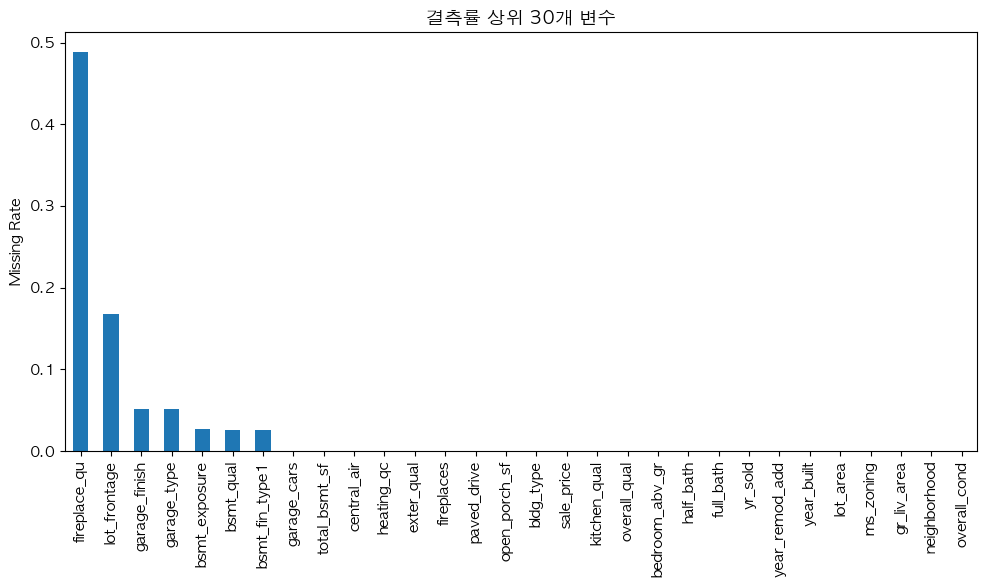


📊 결측률 구간별 변수 개수:
missing_bin
0         22
0~40%      8
40~70%     1
70~80%     0
80% 이상     0
Name: count, dtype: int64


In [5]:
# ============================================
# 3. 결측치 EDA
# ============================================
# 변수별 결측률, 유니크 개수, dtype 정리
summary = pd.DataFrame({
    "dtype": df_train.dtypes,
    "n_unique": df_train.nunique(),
    "missing_cnt": df_train.isna().sum(),
})
summary["missing_rate"] = summary["missing_cnt"] / len(df_train)
summary = summary.sort_values("missing_rate", ascending=False)

print("\n📋 변수 요약 (결측률 상위 10개만 표시):")
print(summary.head(10))

missing_rate = df_train.isna().mean().sort_values(ascending=False)

# 결측률 barplot
plt.figure()
missing_rate.head(30).plot(kind='bar')
plt.title("결측률 상위 30개 변수")
plt.ylabel("Missing Rate")
plt.tight_layout()
plt.show()

# 결측률 구간별 변수 개수 집계
bins = [0, 0.000001, 0.4, 0.7, 0.8, 1.0]
labels = ["0", "0~40%", "40~70%", "70~80%", "80% 이상"]
summary["missing_bin"] = pd.cut(summary["missing_rate"], bins=bins, labels=labels, include_lowest=True)

print("\n📊 결측률 구간별 변수 개수:")
print(summary["missing_bin"].value_counts().sort_index())


In [6]:
# ============================================
# 4. 범주형 변수 EDA (희귀 카테고리 / 범주 수 많은 변수 찾기)
# ============================================
cat_cardinality = df_train[cat_cols].nunique().sort_values(ascending=False)
print("\n🔡 범주 수가 많은 범주형 변수 TOP 15:")
print(cat_cardinality.head(10))

# 범주 수가 10개 초과인 변수 목록 (원핫 vs 기타 인코딩 논의용)
high_card_cols = cat_cardinality[cat_cardinality > 10].index.tolist()
print("\n 범주 수 > 10인 변수들:")
print(high_card_cols)

# Note: 아래 희귀 카테고리 계산은 전체 데이터 비율 기준으로 한 'EDA 참고용'
# 실제 rare category 처리는 OneHotEncoder(min_frequency=0.01)가
# CV의 train fold 기준으로 자동 처리함.

# 각 범주형 변수에서 희귀 카테고리 후보 (비율 < 1%인 범주 수)
rare_info = {}
threshold = 0.01  # 1%
for col in cat_cols:
    vc = df_train[col].value_counts(normalize=True, dropna=True)
    rare_cnt = (vc < threshold).sum()
    rare_info[col] = {
        "n_unique": vc.shape[0],
        "n_rare(<1%)": rare_cnt
    }

rare_df_train = pd.DataFrame(rare_info).T.sort_values("n_rare(<1%)", ascending=False)
print("\n🌱 희귀 카테고리(비율 < 1%) 많은 변수 TOP 10:")
print(rare_df_train.head(10))



🔡 범주 수가 많은 범주형 변수 TOP 15:
neighborhood      28
ms_zoning          7
garage_type        6
bsmt_fin_type1     6
sale_condition     6
bsmt_qual          5
heating_qc         5
fireplace_qu       5
bldg_type          5
kitchen_qual       4
dtype: int64

 범주 수 > 10인 변수들:
['neighborhood']

🌱 희귀 카테고리(비율 < 1%) 많은 변수 TOP 10:
                n_unique  n_rare(<1%)
neighborhood          28            7
ms_zoning              7            3
garage_type            6            2
sale_condition         6            2
bsmt_qual              5            1
heating_qc             5            1
kitchen_qual           4            0
garage_finish          3            0
bsmt_exposure          4            0
bsmt_fin_type1         6            0


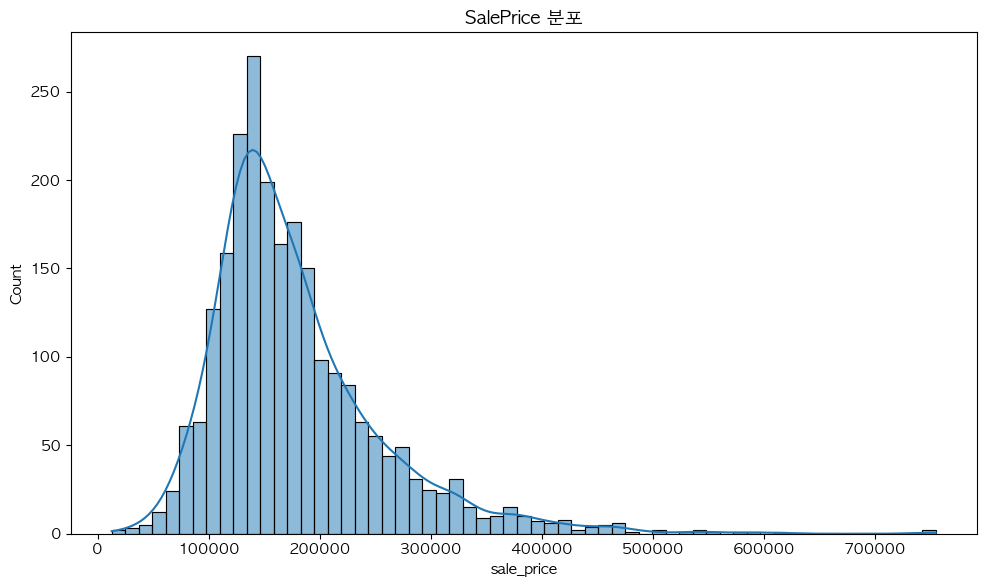

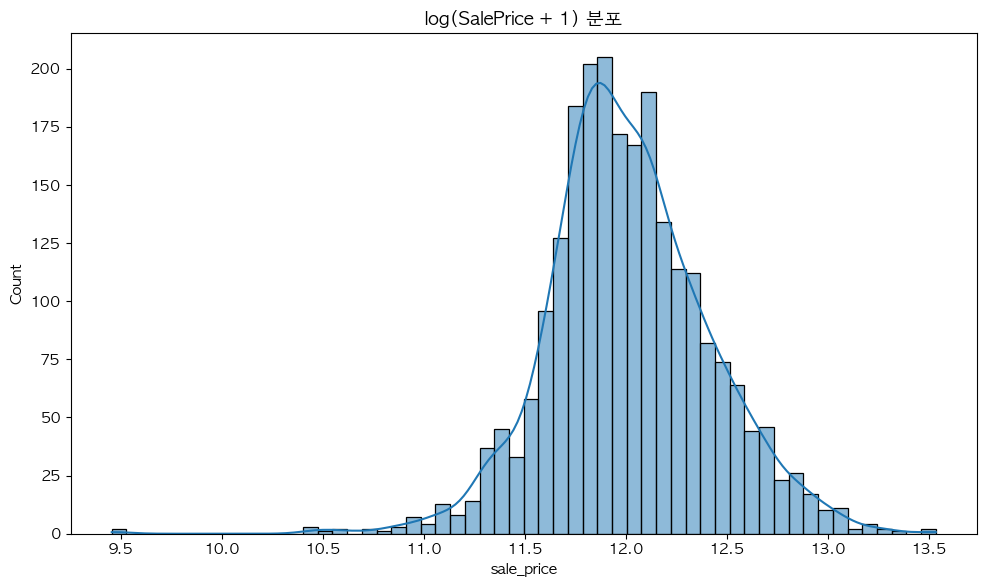


📈 SalePrice와 상관관계 상위 6개 수치형 변수:
sale_price       1.000000
overall_qual     0.795298
gr_liv_area      0.698315
garage_cars      0.644304
total_bsmt_sf    0.612256
year_built       0.545409
Name: sale_price, dtype: float64


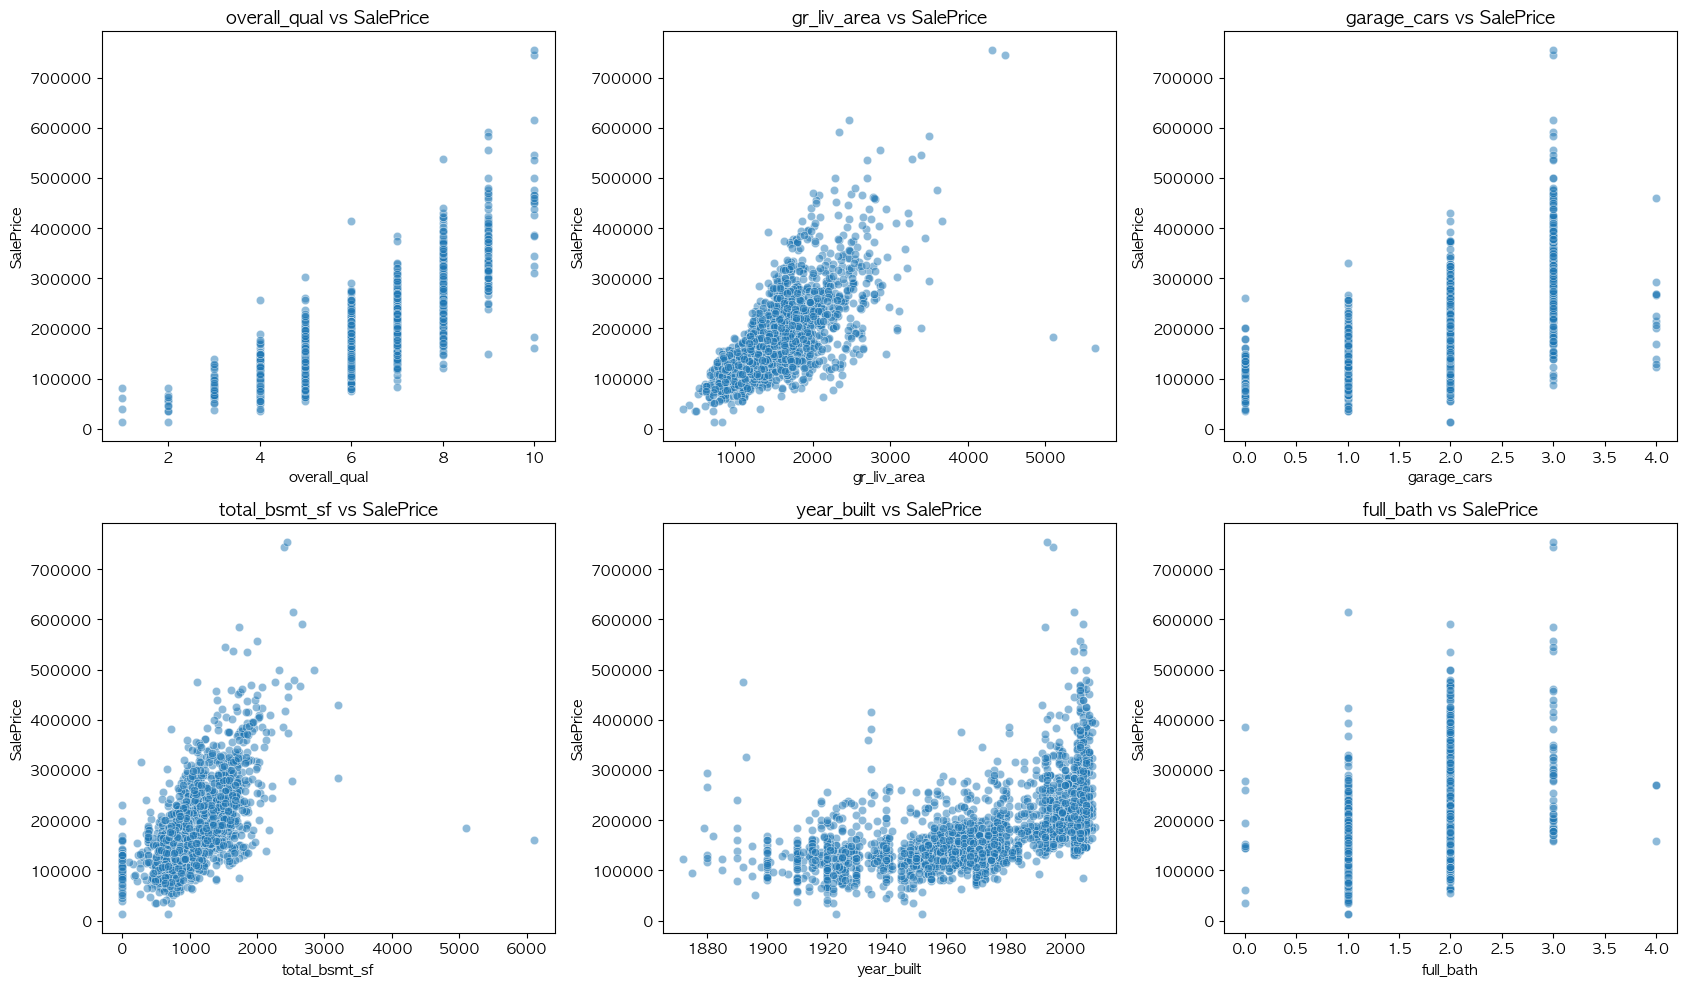

In [7]:
# ============================================
# 5. 수치형 변수 EDA (분포 & 이상치 후보)
# ============================================
# 타깃 변수 이름
target_col = "sale_price"

# 타깃 분포
plt.figure()
sns.histplot(df_train[target_col], kde=True)
plt.title("SalePrice 분포")
plt.tight_layout()
plt.show()

# log 변환 분포
# 1) 왜도(skew) 개선되는지 확인
# 2) 회귀 모델 성능 향상 여부 판단
# 3) 타깃-피처 관계가 선형화되는지 보기 위해
# 4) 로그 변환을 사용할지 결정
plt.figure()
sns.histplot(np.log1p(df_train[target_col]), kde=True)
plt.title("log(SalePrice + 1) 분포")
plt.tight_layout()
plt.show()


# 수치형 변수와 타깃 상관관계
num_cols_no_target = [c for c in num_cols if c != target_col]
corr_with_target = df_train[num_cols_no_target + [target_col]].corr()[target_col].sort_values(ascending=False)

print("\n📈 SalePrice와 상관관계 상위 6개 수치형 변수:")
print(corr_with_target.head(6))


# === 상관 높은 상위 6개변수와 타깃 변수의 산점도 ===
top_num_features = corr_with_target.drop(target_col, errors='ignore').head(6).index.tolist()
# 상관관계는 이상치에 민감하므로 절대적 기준이 아님.
# 단, 변수 중요도나 모형 해석의 참고자료로 활용.


n = len(top_num_features)
cols = 3
rows = (n + cols - 1) // cols  

fig, axes = plt.subplots(rows, cols, figsize=(17, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(top_num_features):
    sns.scatterplot(x=df_train[col], y=df_train[target_col], alpha=0.5, ax=axes[i])
    axes[i].set_title(f"{col} vs SalePrice")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("SalePrice")

# 남는 빈칸 제거
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



🚨 이상치 비율 상위 10개 수치형 변수:
overall_cond      0.083618
lot_frontage      0.073808
open_porch_sf     0.052901
lot_area          0.048208
sale_price        0.045648
total_bsmt_sf     0.040120
gr_liv_area       0.025171
bedroom_abv_gr    0.024744
garage_cars       0.005548
fireplaces        0.005119
dtype: float64


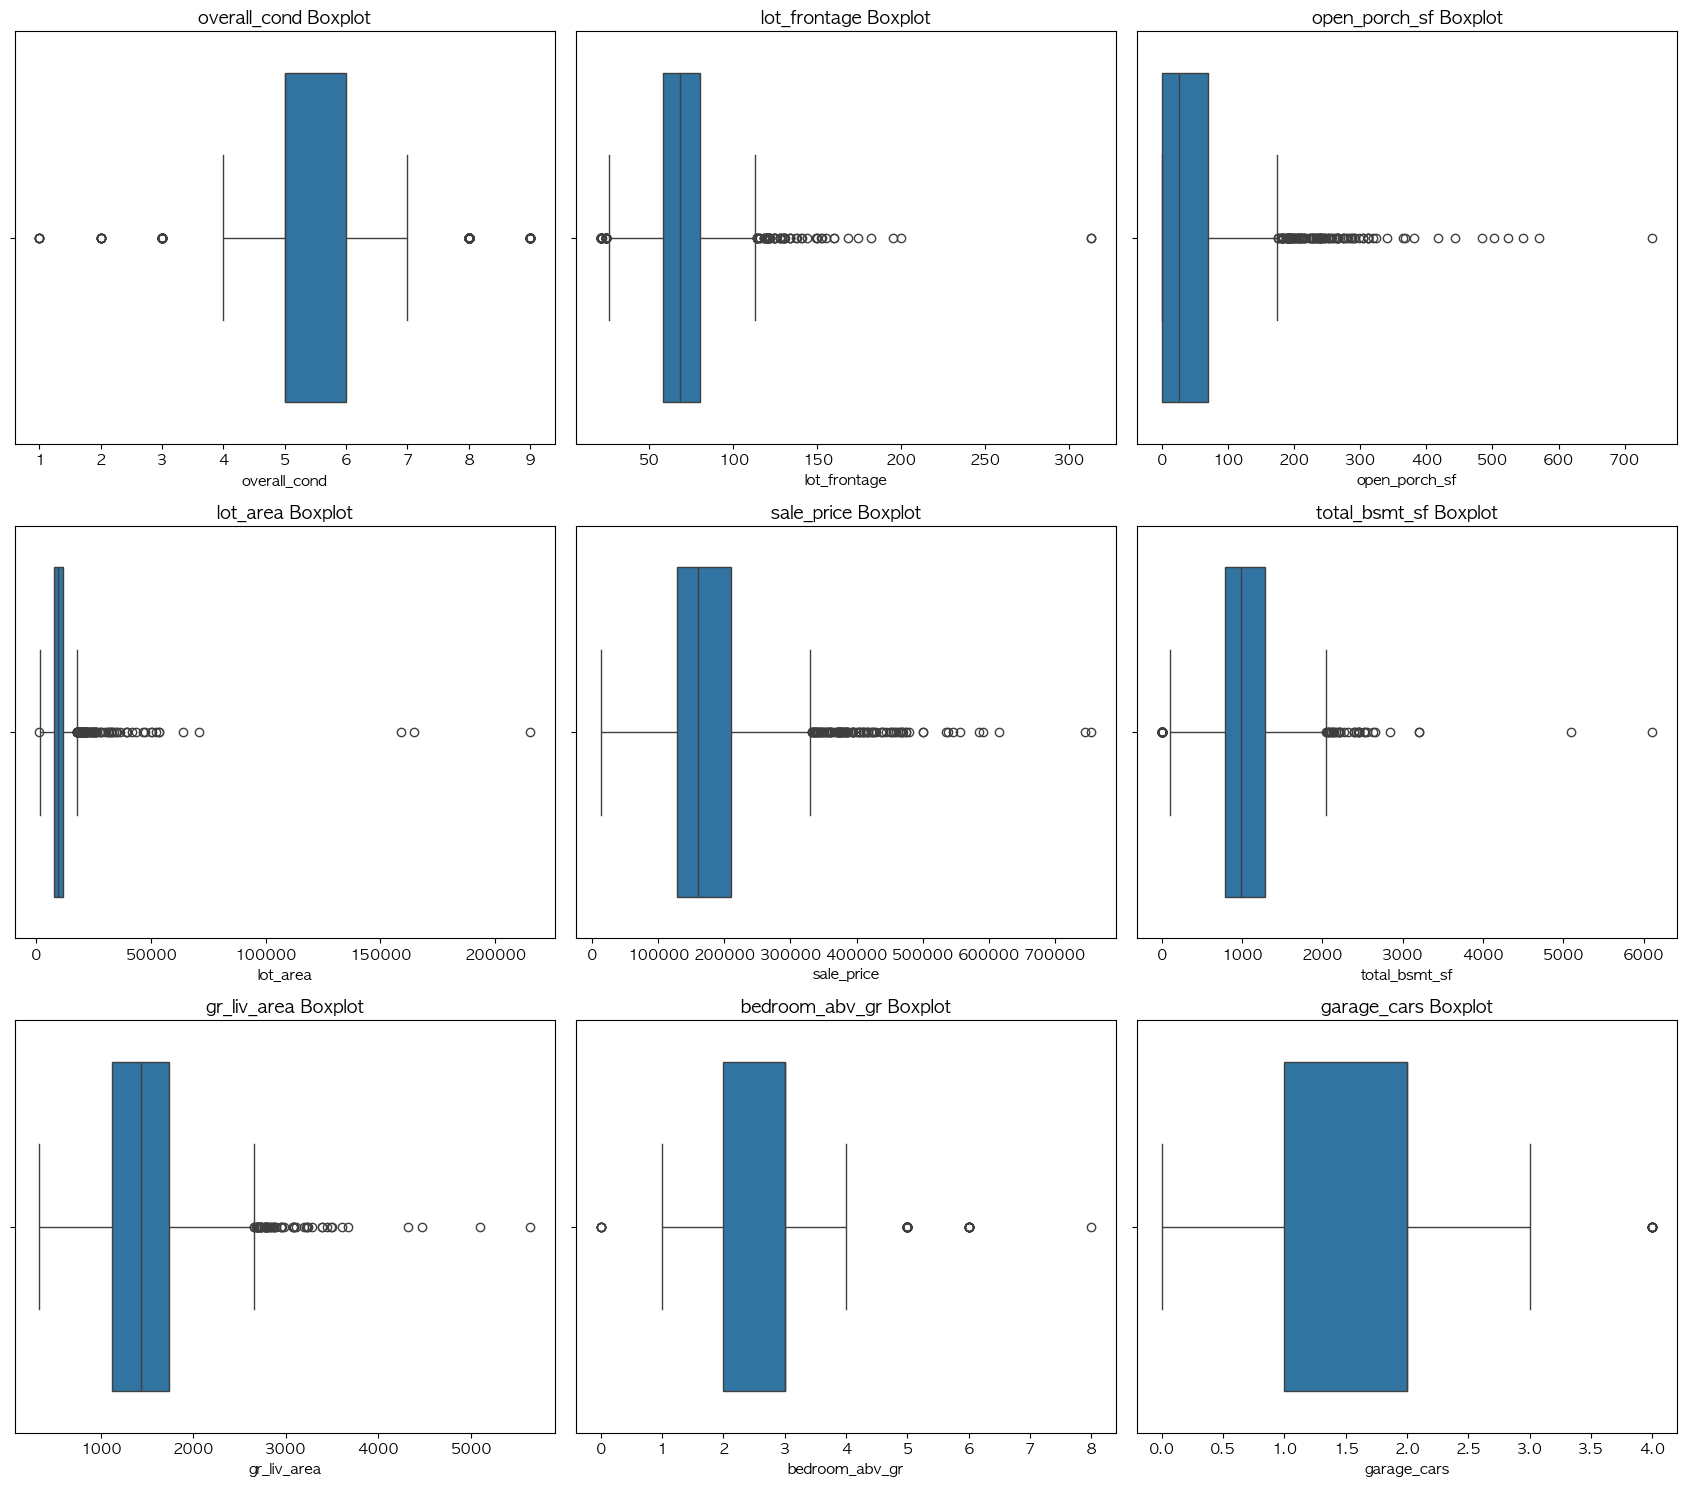

In [8]:
# ============================================
# 6. 이상치 탐지 (IQR 기반 outlier 비율 보기)
# ============================================
# Note: IQR 기반 이상치 탐지는 EDA 목적(변수 분포 이해)이며,
# 실제 모델링에서는 값을 제거하거나 Wynsorize하지 않는다.
# 대신 로그변환 + 규제회귀로 이상치 영향 완충.

outlier_ratio_simple = {}

for col in num_cols:
    s = df_train[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    # 이상치 비율 계산
    outlier_ratio_simple[col] = ((s < lower) | (s > upper)).mean()

outlier_df_train = pd.Series(outlier_ratio_simple).sort_values(ascending=False)

print("\n🚨 이상치 비율 상위 10개 수치형 변수:")
print(outlier_df_train.head(10))

top_outlier_cols = outlier_df_train.head(9).index.tolist()

n = len(top_outlier_cols)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(17, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(top_outlier_cols):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(f"{col} Boxplot")

# 남는 빈칸 제거
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


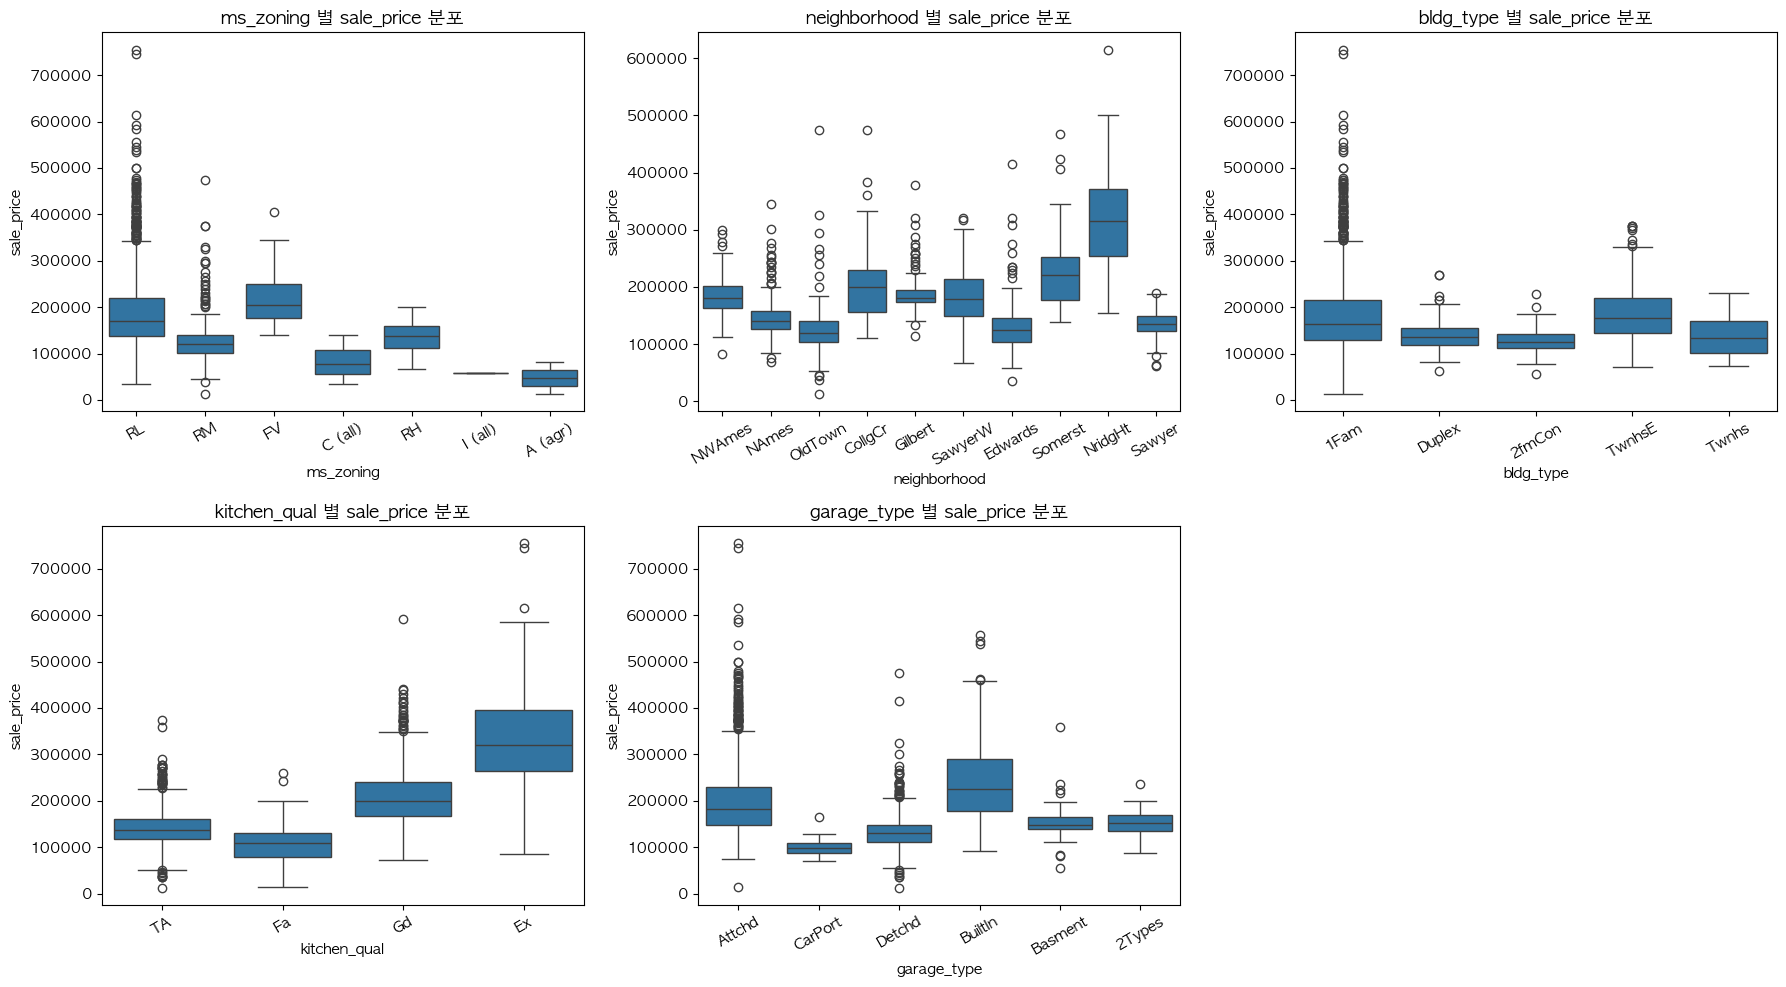

In [9]:
# ============================================
# 7. 범주형 vs 타깃 관계 (박스플롯 예시)
# 범주형 변수 값에 따라 타깃(sale_price)이 어떻게 달라지는지 한눈에 보기 위함
# ============================================
target_col = "sale_price"   # 로그 쓴다면 "sale_price_log" 같은 이름으로 바꿔도 됨

# regression_description_v2 기준 Simplified Name 사용
cat_for_box = ["ms_zoning", "neighborhood", "bldg_type", "kitchen_qual", "garage_type"]

n = len(cat_for_box)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(cat_for_box):
    # 카테고리가 너무 많으면 상위 10개만
    top_k = df_train[col].value_counts().head(10).index
    temp = df_train[df_train[col].isin(top_k)]
    
    sns.boxplot(x=col, y=target_col, data=temp, ax=axes[i])
    axes[i].set_title(f"{col} 별 {target_col} 분포")
    axes[i].tick_params(axis='x', rotation=30)

# 남는 빈칸 제거
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# 전처리

In [3]:
# 타깃 / 피처 분리 (train만!)
y_train = df_train["sale_price"]     # 타깃
X_train = df_train.drop(columns=["sale_price"]) # 피처
X_test  = df_test.copy()                        # 피처(타깃 없음)

# 수치형 / 범주형 컬럼 분리 (train 기준)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [4]:
# ==========================================
# 📌 1) 구조적 결측 처리 (train + test 동일 규칙 적용)
# ==========================================

for df in [X_train, X_test]:
    # fireplace_qu → 결측 = "None"
    df['fireplace_qu'] = df['fireplace_qu'].fillna("None")

    # garage_type / garage_finish → 결측 = "None"
    df['garage_type'] = df['garage_type'].fillna("None")
    df['garage_finish'] = df['garage_finish'].fillna("None")

    # Basement 관련 변수들 → 결측 = "NoBasement"
    basement_cols = ['bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1']
    for col in basement_cols:
        df[col] = df[col].fillna("NoBasement")

    # garage_cars / total_bsmt_sf → 결측 = 0
    df['garage_cars'] = df['garage_cars'].fillna(0)
    df['total_bsmt_sf'] = df['total_bsmt_sf'].fillna(0)
    
print(df[['fireplace_qu','garage_type','garage_finish','bsmt_qual', 'bsmt_exposure', 'bsmt_fin_type1','garage_cars','total_bsmt_sf']])



    fireplace_qu garage_type garage_finish bsmt_qual bsmt_exposure  \
0             Gd      Detchd           Unf        TA            No   
1           None      Detchd           Unf        TA            No   
2             Gd     BuiltIn           Fin        Gd            No   
3           None        None          None        Gd            No   
4           None      Detchd           Unf        TA            No   
..           ...         ...           ...       ...           ...   
581           Gd      Attchd           Fin        Ex            Av   
582           Ex      Attchd           Fin        Ex            Gd   
583           TA      Attchd           RFn        Gd            No   
584           Fa      Attchd           Unf        Gd            Gd   
585         None      Attchd           Fin        TA            No   

    bsmt_fin_type1  garage_cars  total_bsmt_sf  
0              Unf          1.0          588.0  
1              ALQ          1.0          494.0  
2           

In [6]:

# ==========================================
# 📌 2) 비구조적 결측 처리
# ==========================================

# train 기준으로 동네별 median 계산
nbhd_median = X_train.groupby('neighborhood')['lot_frontage'].median()

# train / test 둘 다 같은 규칙 적용
for df in [X_train, X_test]:
    df['lot_frontage'] = df['lot_frontage'].fillna(
        df['neighborhood'].map(nbhd_median)
    )

# median 채우기
for col in num_cols:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col]  = X_test[col].fillna(med)

# 최빈값(most frequent) 채우기
for col in cat_cols:
    mode = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode)
    X_test[col]  = X_test[col].fillna(mode)



In [7]:
# ==========================================
# 📌 3) 희귀 카테고리 병합 (비율 < 1%)
# ==========================================

rare_threshold = 0.01
rare_cols = ["neighborhood"]

for col in rare_cols:
    freq = df_train[col].value_counts(normalize=True)
    rare = freq[freq < rare_threshold].index  # 희귀값 목록
    
    df_train[col] = df_train[col].replace(rare, "Rare")
    df_test[col]  = df_test[col].replace(rare, "Rare")


In [8]:
# ==========================================
# 📌 4) 순서형 데이터 인코딩
# ==========================================

ordinal_cols = [
    'exter_qual',
    'kitchen_qual',
    'heating_qc',
    'fireplace_qu',
    'bsmt_qual'
]

ordinal_map = {
    "NoBasement": 0,
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

garage_finish_map = {
    'None': 0,
    'Unf': 1,
    'RFn': 2,
    'Fin': 3
}

bsmtfin1_map = {
    'NoBasement': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
}

bsmt_exposure_map = {
    "NoBasement": 0,
    "No": 1,
    "Mn": 2,
    "Av": 3,
    "Gd": 4
}

for df in [X_train, X_test]:
    # (1) 품질형 ordinal 인코딩
    for col in ordinal_cols:
        df[col] = df[col].map(ordinal_map)

    # (2) garage_finish
    df['garage_finish'] = df['garage_finish'].map(garage_finish_map)

    # (3) bsmt_fin_type1
    df['bsmt_fin_type1'] = df['bsmt_fin_type1'].map(bsmtfin1_map)

    # (4) bsmt_exposure
    df['bsmt_exposure'] = df['bsmt_exposure'].map(bsmt_exposure_map)

    # 혹시 매핑 안 된 값 존재하면 최저 등급(0) 처리
    # for col in ordinal_cols:
    #    df[col] = df[col].fillna(0)
    # df['garage_finish'] = df['garage_finish'].fillna(0)
    # df['bsmt_fin_type1'] = df['bsmt_fin_type1'].fillna(0)
    # df['bsmt_exposure'] = df['bsmt_exposure'].fillna(0)
    
print(df[['garage_finish','bsmt_fin_type1','bsmt_exposure']])
print(df.loc[:,ordinal_cols])

     garage_finish  bsmt_fin_type1  bsmt_exposure
0                1               1              1
1                1               5              1
2                3               1              1
3                0               6              1
4                1               3              1
..             ...             ...            ...
581              3               6              3
582              3               6              4
583              2               1              1
584              1               5              4
585              3               4              1

[586 rows x 3 columns]
     exter_qual  kitchen_qual  heating_qc  fireplace_qu  bsmt_qual
0             3             4           2             4          3
1             3             3           5             0          3
2             4             4           5             4          4
3             3             3           5             0          4
4             3             3           3

In [9]:
# ==========================================
# 📌 5) 파생변수 생성 (행 단위 계산, train/test 둘 다)
# ==========================================

for df in [X_train, X_test]:
    # (1) 총 면적: 지상 + 지하
    df['total_sf'] = df['total_bsmt_sf'] + df['gr_liv_area']
    
    # (2) 집 나이: 팔린 연도 - 지어진 연도
    df['house_age'] = df['yr_sold'] - df['year_built']

print(df[['total_sf','house_age']])

     total_sf  house_age
0      2254.0         83
1      1524.0         34
2      2520.0          3
3      1980.0         13
4      1813.0         82
..        ...        ...
581    2014.0          4
582    4984.0          5
583    2810.0          6
584    1872.0         40
585    2512.0         43

[586 rows x 2 columns]


In [10]:
# ==========================================
# 📌 6) 원 핫 인코딩
# ==========================================
# 범주형 원핫
X_train_ohe = pd.get_dummies(X_train, drop_first=True)
X_test_ohe  = pd.get_dummies(X_test,  drop_first=True)

# train/test 열 맞추기
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

print(X_train_ohe)


      overall_qual  overall_cond  gr_liv_area  lot_area  lot_frontage  \
0                7             5         1370     10400          80.0   
1                5             5         2126     28698          80.5   
2                4             5         1224      9842          70.0   
3                4             5         1040      7200          60.0   
4                4             6         1701      7627          63.0   
...            ...           ...          ...       ...           ...   
2339             5             5         1424     41600         195.0   
2340             7             5         1414      7750          63.0   
2341             6             5         1728      8791          64.0   
2342             5             5         1740      7308          81.0   
2343             5             8          768      7200          60.0   

      total_bsmt_sf  year_built  year_remod_add  yr_sold  full_bath  ...  \
0            1090.0        1976            1976

In [18]:
# ==========================================
# 📌 7) 표준화
# ==========================================

# 스케일링은 원핫 이후 수치형 컬럼만 선택
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
X_train_ohe[num_cols] = scaler.fit_transform(X_train_ohe[num_cols])
X_test_ohe[num_cols]  = scaler.transform(X_test_ohe[num_cols])



# 모델링

In [11]:
# 공통 CV 설정
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# ==========================================
# 📌 elastic net
# ==========================================

# 변수명 재설정
X_train = X_train_ohe.copy()
X_test  = X_test_ohe.copy()


enet = ElasticNet(max_iter=50000, random_state=42)

param_grid_enet = {
    'alpha': [
        0.0001, 0.0003,
        0.001,  0.003,
        0.01,   0.03,
        0.1,    0.3,
        1.0
    ],
    'l1_ratio': [0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
}


cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_enet = GridSearchCV(
    estimator=enet,
    param_grid=param_grid_enet,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

grid_enet.fit(X_train, y_train)

print("Best params:", grid_enet.best_params_)
print("Best CV RMSE:", -grid_enet.best_score_)



/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.471e+11, tolerance: 1.111e+09
  model = cd_fast.enet_coordinate_descent(
/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.180e+11, tolerance: 1.083e+09
  model = cd_fast.enet_coordinate_descent(
/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasi

Best params: {'alpha': 0.03, 'l1_ratio': 0.9}
Best CV RMSE: 30146.307666409306


/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.497e+11, tolerance: 1.394e+09
  model = cd_fast.enet_coordinate_descent(


# 데이터 저장 및 재현성 확인

In [30]:
# ==========================================
# 📦 7) 최종 모델 추출 & 예측값 생성
# ==========================================
import numpy as np
import pandas as pd
import joblib

# 1) GridSearchCV에서 최적 ElasticNet 모델 꺼내기
best_model = grid_enet.best_estimator_
print("✅ 최종 모델(best_model):", best_model)

# 2) Train / Test 예측 (로그 스케일 → 원 스케일 복구)

# (1) Train 예측
y_pred_train = best_model.predict(X_train)     # 로그 스케일

# (2) Test 예측
y_pred_test = best_model.predict(X_test)      # 로그 스케일

print("Train 예측 개수:", len(y_pred_train))
print("Test 예측 개수:", len(y_pred_test))


✅ 최종 모델(best_model): ElasticNet(alpha=0.03, l1_ratio=0.9, max_iter=50000, random_state=42)
Train 예측 개수: 2344
Test 예측 개수: 586


In [31]:
# ==========================================
# 📄 8) submission_train.csv 생성
# ==========================================

# 1) 전처리된 feature 복사
df_sub_train = X_train.copy()

# 2) y_true, y_pred 추가 (둘 다 원 스케일)
df_sub_train["y_true"] = df_train["sale_price"].values
df_sub_train["y_pred"] = y_pred_train

# 3) 컬럼 순서 정리: [feature들] + [y_true] + [y_pred]
feature_cols = X_train.columns.tolist()
df_sub_train = df_sub_train[feature_cols + ["y_true", "y_pred"]]

# 4) 저장
# df_sub_train[["y_true", "y_pred"]] = df_sub_train[["y_true", "y_pred"]].round(10)
df_sub_train.to_csv("submission_train.csv", index=False,float_format="%.17f")
print("✅ submission_train.csv 저장 완료,", "shape:", df_sub_train.shape)


✅ submission_train.csv 저장 완료, shape: (2344, 78)


In [32]:
# ==========================================
# 📄 9) submission_test.csv 생성
# ==========================================

df_sub_test = X_test.copy()
df_sub_test["y_pred"] = y_pred_test   # 원 스케일 예측값

# Train과 feature 순서를 정확히 맞추기 위해 X_train 기준으로 정렬
feature_cols_test = X_train.columns.tolist()
df_sub_test = df_sub_test[feature_cols_test + ["y_pred"]]

# df_sub_test["y_pred"]=df_sub_test["y_pred"].round(10)
df_sub_test.to_csv("submission_test.csv", index=False,float_format="%.17f")
print("✅ submission_test.csv 저장 완료,", "shape:", df_sub_test.shape)


✅ submission_test.csv 저장 완료, shape: (586, 77)


In [33]:
# ==========================================
# 💾 10) 최종 모델 객체 저장 (model.pkl)
# ==========================================

joblib.dump(best_model, "model.pkl")
print("✅ model.pkl 저장 완료")


✅ model.pkl 저장 완료


In [35]:
import pandas as pd
import joblib

# 1. 길이 확인
df_train_pub = pd.read_csv('regression_train_public.csv')  # 회귀: regression_train_public.csv
df_sub_train = pd.read_csv('submission_train.csv')
df_sub_test = pd.read_csv('submission_test.csv')

print(f"Train 원본: {len(df_train_pub)}, 제출: {len(df_sub_train)}")  # 같아야 함
# Test 길이는 제공된 test_private.csv와 비교

# 2. 재현성 확인 (Test)
model = joblib.load('model.pkl')
X_test = df_sub_test.drop(columns=['y_pred'])
y_pred_saved = df_sub_test['y_pred']
y_pred_reload = model.predict(X_test)

print(f"예측 일치: {(y_pred_saved == y_pred_reload).all()}")  # True여야 함

# 3. 재현성 확인 (Train)
X_train = df_sub_train.drop(columns=['y_true', 'y_pred'])
y_pred_train_saved = df_sub_train['y_pred']
y_pred_train_reload = model.predict(X_train)

print(f"Train 예측 일치: {(y_pred_train_saved == y_pred_train_reload).all()}")  # True여야 함



Train 원본: 2344, 제출: 2344
예측 일치: False
Train 예측 일치: False


# 나머지 모델

In [15]:
# ===============================
# 📌 Ridge 모델 + GridSearchCV
# ===============================
ridge = Ridge(random_state=42)

param_grid_ridge = {
    'alpha': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]
}

grid_ridge = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid_ridge,
    scoring='neg_root_mean_squared_error',  # RMSE 기준
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_ridge.fit(X_train, y_train)

print("\n🔹 [Ridge CV 결과]")
print("Best params (Ridge):", grid_ridge.best_params_)
print("Best CV RMSE (log 스케일):", -grid_ridge.best_score_)

# (선택) train 성능 확인
# best_ridge = grid_ridge.best_estimator_

#evaluate_model(
#    name="Ridge (Train)",
#    estimator=best_ridge,
#    X_test=X_train,
#    y_test_log=y_train)


Fitting 5 folds for each of 8 candidates, totalling 40 fits

🔹 [Ridge CV 결과]
Best params (Ridge): {'alpha': 3}
Best CV RMSE (log 스케일): 30163.453516280984


In [37]:
# ===============================
# 📌 Lasso 모델 + GridSearchCV
# ===============================
lasso = Lasso(max_iter=50000, random_state=42)

param_grid_lasso = {
    'alpha': [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
}

grid_lasso = GridSearchCV(
    estimator=lasso,
    param_grid=param_grid_lasso,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_lasso.fit(X_train, y_train)

print("\n🔹 [Lasso CV 결과]")
print("Best params (Lasso):", grid_lasso.best_params_)
print("Best CV RMSE (log 스케일):", -grid_lasso.best_score_)

# (선택) train 성능 확인
#best_lasso = grid_lasso.best_estimator_

#evaluate_model(
#    name="Lasso (Train)",
#    estimator=best_lasso,
#    X_test=X_train,
#    y_test_log=y_train)


Fitting 5 folds for each of 7 candidates, totalling 35 fits


/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591e+11, tolerance: 1.111e+09
  model = cd_fast.enet_coordinate_descent(
/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.938e+11, tolerance: 1.138e+09
  model = cd_fast.enet_coordinate_descent(
/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasi


🔹 [Lasso CV 결과]
Best params (Lasso): {'alpha': 0.1}
Best CV RMSE (log 스케일): 30291.323494414763


/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.365e+11, tolerance: 1.394e+09
  model = cd_fast.enet_coordinate_descent(


In [ ]:
from sklearn.feature_selection import SelectFromModel
best_lasso = grid_lasso.best_estimator_

# ==========================================
# 📌 (1) Lasso로 변수 선택 (Feature Selection)
# ==========================================
# 위에서 구한 best_lasso 사용 (grid_lasso.best_estimator_)
selector = SelectFromModel(
    estimator=best_lasso,   # 이미 학습된 Lasso
    prefit=True,
    threshold='mean'        # 중요도(계수 절댓값)의 평균 이상만 선택
)

X_train_sel = selector.transform(X_train)
X_test_sel  = selector.transform(X_test)

print("\n선택된 변수 개수:", X_train_sel.shape[1], "/", X_train.shape[1])

# ==========================================
# 📌 (2) 선택된 변수만 가지고 Ridge 그리드서치
# ==========================================
ridge_fs = Ridge(random_state=42)

param_grid_ridge_fs = {
    'alpha': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]
}

grid_ridge_fs = GridSearchCV(
    estimator=ridge_fs,
    param_grid=param_grid_ridge_fs,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_ridge_fs.fit(X_train_sel, y_train)

print("\n🔹 [Lasso 선택 변수 + Ridge CV 결과]")
print("Best params (Lasso+Ridge):", grid_ridge_fs.best_params_)
print("Best CV RMSE :", -grid_ridge_fs.best_score_)

# (선택) train 성능 확인
# best_ridge_fs = grid_ridge_fs.best_estimator_

#evaluate_model(
#    name="Lasso 선택 변수 + Ridge (Train)",
#    estimator=best_ridge_fs,
#    X_test=X_train_sel,
#    y_test_log=y_train)



선택된 변수 개수: 21 / 76
Fitting 5 folds for each of 8 candidates, totalling 40 fits

🔹 [Lasso 선택 변수 + Ridge CV 결과]
Best params (Lasso+Ridge): {'alpha': 1}
Best CV RMSE (log 스케일): 43540.34344621937


/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/Users/jw/project/school/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
